## Improvement to the model

In [14]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42

In [15]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "train_FD001.txt"

RESULTS_PATH = PROJECT_ROOT / "results"
FIGURES_PATH = RESULTS_PATH / "figures"
METRICS_PATH = RESULTS_PATH / "metrics"

FIGURES_PATH.mkdir(parents=True, exist_ok=True)
METRICS_PATH.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Training file exists:", DATA_PATH.exists())

Project folder: /Users/aisha/mma3001-project
Training file exists: True


In [16]:
index_columns = [
    "engine_id",
    "cycle",
]

setting_columns = [
    "setting_1",
    "setting_2",
    "setting_3",
]

sensor_columns = [
    f"sensor_{number}" for number in range(1, 22)
]

column_names = (
    index_columns
    + setting_columns
    + sensor_columns
)

print("Number of columns:", len(column_names))

Number of columns: 26


In [17]:
train = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    names=column_names
)

print("Dataset shape:", train.shape)
print("Number of engines:", train["engine_id"].nunique())

train.head()

Dataset shape: (20631, 26)
Number of engines: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [18]:
maximum_cycles = (
    train.groupby("engine_id")["cycle"]
    .max()
    .rename("maximum_cycle")
)

train = train.merge(
    maximum_cycles,
    on="engine_id",
    how="left",
    validate="many_to_one"
)

train["RUL_raw"] = (
    train["maximum_cycle"]
    - train["cycle"]
)

train[
    [
        "engine_id",
        "cycle",
        "maximum_cycle",
        "RUL_raw"
    ]
].head()

,engine_id,cycle,maximum_cycle,RUL_raw
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187


In [20]:
RUL_CAP = 125

train["RUL_capped"] = train[
    "RUL_raw"
].clip(
    upper=RUL_CAP
)

print(
    train[
        ["RUL_raw", "RUL_capped"]
    ].describe()
)

            RUL_raw    RUL_capped
count  20631.000000  20631.000000
mean     107.807862     86.829286
std       68.880990     41.673699
min        0.000000      0.000000
25%       51.000000     51.000000
50%      103.000000    103.000000
75%      155.000000    125.000000
max      361.000000    125.000000


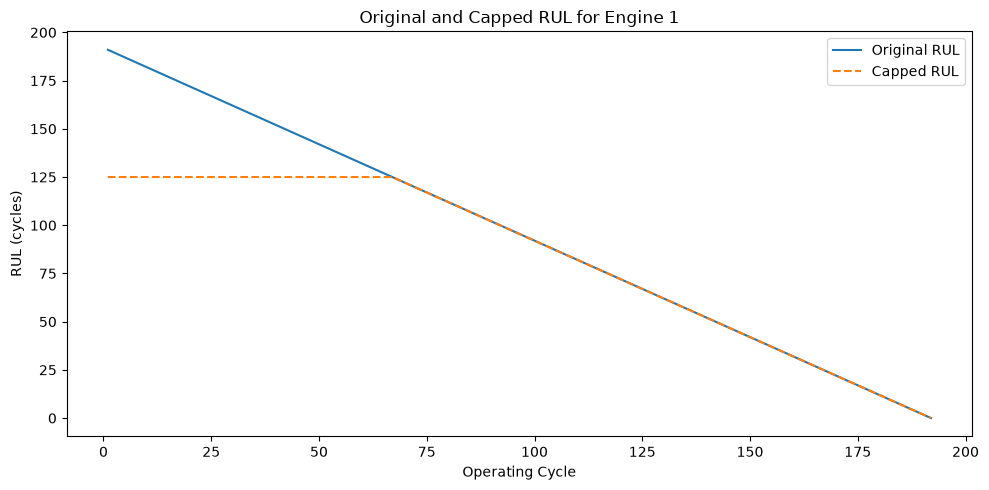

In [21]:
plt.figure(figsize=(10, 5))

engine_1 = train[
    train["engine_id"] == 1
]

plt.plot(
    engine_1["cycle"],
    engine_1["RUL_raw"],
    label="Original RUL"
)

plt.plot(
    engine_1["cycle"],
    engine_1["RUL_capped"],
    label="Capped RUL",
    linestyle="--"
)

plt.xlabel("Operating Cycle")
plt.ylabel("RUL (cycles)")
plt.title(
    "Original and Capped RUL for Engine 1"
)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "rul_capping_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
sensor_statistics = train[
    sensor_columns
].agg(
    ["mean", "std", "min", "max"]
).T

constant_sensors = sensor_statistics[
    sensor_statistics["std"] < 1e-8
].index.tolist()

usable_sensors = [
    sensor
    for sensor in sensor_columns
    if sensor not in constant_sensors
]

print("Constant sensors:")
print(constant_sensors)

print("\nUsable sensors:")
print(usable_sensors)

print(
    "\nNumber of usable sensors:",
    len(usable_sensors)
)

Constant sensors:
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Usable sensors:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Number of usable sensors: 15


In [23]:
ROLLING_WINDOW = 5

for sensor in usable_sensors:
    train[
        f"{sensor}_rolling_mean"
    ] = (
        train
        .groupby("engine_id")[sensor]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=1
            ).mean()
        )
    )

In [24]:
for sensor in usable_sensors:
    train[
        f"{sensor}_rolling_std"
    ] = (
        train
        .groupby("engine_id")[sensor]
        .transform(
            lambda x: x.rolling(
                window=ROLLING_WINDOW,
                min_periods=2
            ).std()
        )
    )

In [25]:
for sensor in usable_sensors:
    train[
        f"{sensor}_delta"
    ] = (
        train
        .groupby("engine_id")[sensor]
        .diff()
        .fillna(0)
    )

In [26]:
baseline_features = (
    ["cycle"]
    + setting_columns
    + usable_sensors
)

rolling_mean_features = [
    f"{sensor}_rolling_mean"
    for sensor in usable_sensors
]

rolling_std_features = [
    f"{sensor}_rolling_std"
    for sensor in usable_sensors
]

delta_features = [
    f"{sensor}_delta"
    for sensor in usable_sensors
]

enhanced_features = (
    baseline_features
    + rolling_mean_features
    + rolling_std_features
    + delta_features
)

print(
    "Baseline features:",
    len(baseline_features)
)

print(
    "Enhanced features:",
    len(enhanced_features)
)

Baseline features: 19
Enhanced features: 64


In [27]:
groups = train[
    "engine_id"
].copy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

all_indices = np.arange(
    len(train)
)

train_indices, validation_indices = next(
    splitter.split(
        all_indices,
        groups=groups
    )
)

training_engines = set(
    groups.iloc[train_indices]
)

validation_engines = set(
    groups.iloc[validation_indices]
)

print(
    "Training engines:",
    len(training_engines)
)

print(
    "Validation engines:",
    len(validation_engines)
)

print(
    "Shared engines:",
    training_engines
    & validation_engines
)

assert training_engines.isdisjoint(
    validation_engines
)

Training engines: 80
Validation engines: 20
Shared engines: set()


In [28]:
def evaluate_model(
    name,
    y_true,
    y_prediction
):
    """Calculate regression performance metrics."""

    mae = mean_absolute_error(
        y_true,
        y_prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_prediction
        )
    )

    r_squared = r2_score(
        y_true,
        y_prediction
    )

    return {
        "model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r_squared,
    }

In [29]:
X_baseline = train[
    baseline_features
].copy()

y_original = train[
    "RUL_raw"
].copy()

X_train_baseline = X_baseline.iloc[
    train_indices
]

X_validation_baseline = X_baseline.iloc[
    validation_indices
]

y_train_original = y_original.iloc[
    train_indices
]

y_validation_original = y_original.iloc[
    validation_indices
]

In [30]:
baseline_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

baseline_rf.fit(
    X_train_baseline,
    y_train_original
)

baseline_predictions = baseline_rf.predict(
    X_validation_baseline
)

results = [
    evaluate_model(
        "Original RF",
        y_validation_original,
        baseline_predictions
    )
]

pd.DataFrame(results).round(3)

,model,MAE,RMSE,R2
0,Original RF,23.782,31.312,0.773


In [ ]:
y_capped = train[
    "RUL_capped"
].copy()

y_train_capped = y_capped.iloc[
    train_indices
]

y_validation_capped = y_capped.iloc[
    validation_indices
]

capped_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

capped_rf.fit(
    X_train_baseline,
    y_train_capped
)

capped_predictions = capped_rf.predict(
    X_validation_baseline
)

results.append(
    evaluate_model(
        "RF + capped RUL",
        y_validation_capped,
        capped_predictions
    )
)

pd.DataFrame(results).round(3)

,model,MAE,RMSE,R2
0,Original RF,23.782,31.312,0.773
1,RF + capped RUL,10.820,15.986,0.853


In [32]:
X_enhanced = train[
    enhanced_features
].copy()

X_train_enhanced = X_enhanced.iloc[
    train_indices
]

X_validation_enhanced = X_enhanced.iloc[
    validation_indices
]

In [33]:
enhanced_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

enhanced_rf.fit(
    X_train_enhanced,
    y_train_capped
)

enhanced_predictions = enhanced_rf.predict(
    X_validation_enhanced
)

results.append(
    evaluate_model(
        "RF + capped RUL + trends",
        y_validation_capped,
        enhanced_predictions
    )
)

results_table = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

results_table.round(3)

,model,MAE,RMSE,R2
0,RF + capped RUL + trends,10.027,15.208,0.867
1,RF + capped RUL,10.820,15.986,0.853
2,Original RF,23.782,31.312,0.773


In [34]:
rf_model = enhanced_rf.named_steps[
    "regressor"
]

feature_importance = pd.DataFrame(
    {
        "feature": enhanced_features,
        "importance":
            rf_model.feature_importances_
    }
).sort_values(
    "importance",
    ascending=False
)

feature_importance.head(20)

,feature,importance
21,sensor_4_rolling_mean,0.597525
0,cycle,0.140597
26,sensor_11_rolling_mean,0.069768
25,sensor_9_rolling_mean,0.028940
30,sensor_15_rolling_mean,0.019818
29,sensor_14_rolling_mean,0.015327
10,sensor_9,0.012085
23,sensor_7_rolling_mean,0.011555
33,sensor_21_rolling_mean,0.008293
19,sensor_2_rolling_mean,0.006290


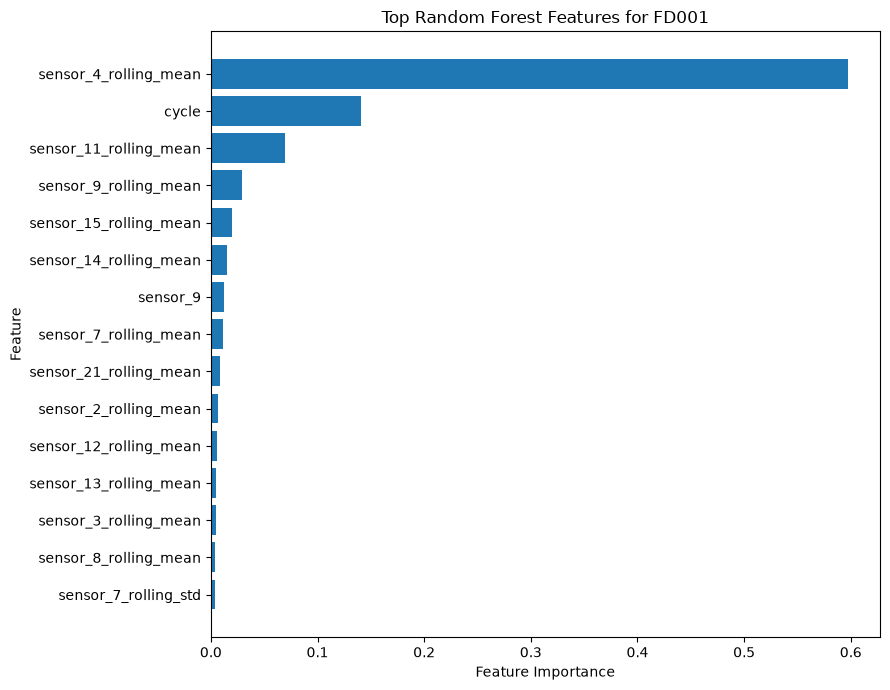

In [35]:
top_features = feature_importance.head(
    15
).sort_values(
    "importance"
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top Random Forest Features for FD001"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH / "improved_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
parameter_options = [
    {
        "n_estimators": 100,
        "max_depth": 10,
        "min_samples_leaf": 2,
        "max_features": 1.0,
    },
    {
        "n_estimators": 200,
        "max_depth": 15,
        "min_samples_leaf": 2,
        "max_features": 1.0,
    },
    {
        "n_estimators": 300,
        "max_depth": 15,
        "min_samples_leaf": 4,
        "max_features": 1.0,
    },
    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 4,
        "max_features": "sqrt",
    },
    {
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_leaf": 2,
        "max_features": 0.5,
    },
]

In [37]:
tuning_results = []

for params in parameter_options:

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "regressor",
                RandomForestRegressor(
                    **params,
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_capped
    )

    predictions = model.predict(
        X_validation_enhanced
    )

    metrics = evaluate_model(
        "Random Forest",
        y_validation_capped,
        predictions
    )

    tuning_results.append(
        {
            **params,
            **metrics,
        }
    )

tuning_table = (
    pd.DataFrame(tuning_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

tuning_table.round(3)

,n_estimators,max_depth,min_samples_leaf,max_features,model,MAE,RMSE,R2
0,300,NaN,4,sqrt,Random Forest,10.067,14.428,0.880
1,300,20.0,2,0.5,Random Forest,9.818,14.763,0.875
2,100,10.0,2,1.0,Random Forest,10.018,15.106,0.869
3,300,15.0,4,1.0,Random Forest,10.012,15.153,0.868
4,200,15.0,2,1.0,Random Forest,10.019,15.154,0.868


In [38]:
best_row = tuning_table.iloc[0]

best_parameters = {
    "n_estimators":
        int(best_row["n_estimators"]),

    "max_depth":
        (
            None
            if pd.isna(best_row["max_depth"])
            else int(best_row["max_depth"])
        ),

    "min_samples_leaf":
        int(best_row["min_samples_leaf"]),

    "max_features":
        best_row["max_features"],
}

print("Best parameters:")
print(best_parameters)

Best parameters:
{'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 4, 'max_features': 'sqrt'}


In [39]:
best_rf = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "regressor",
            RandomForestRegressor(
                **best_parameters,
                n_jobs=-1,
                random_state=RANDOM_STATE
            )
        ),
    ]
)

best_rf.fit(
    X_train_enhanced,
    y_train_capped
)

best_predictions = best_rf.predict(
    X_validation_enhanced
)

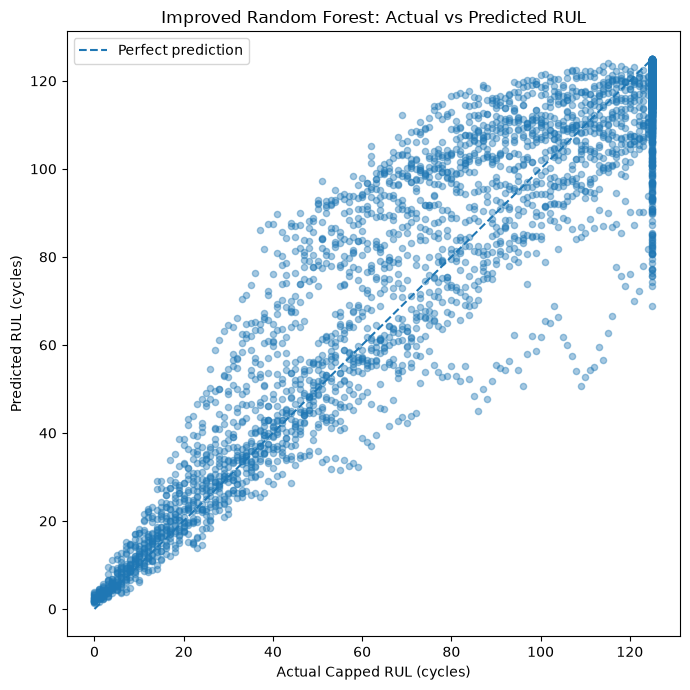

In [40]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_validation_capped,
    best_predictions,
    alpha=0.4,
    s=20
)

minimum_value = min(
    y_validation_capped.min(),
    best_predictions.min()
)

maximum_value = max(
    y_validation_capped.max(),
    best_predictions.max()
)

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Capped RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")

plt.title(
    "Improved Random Forest: "
    "Actual vs Predicted RUL"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_PATH /
    "improved_validation_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

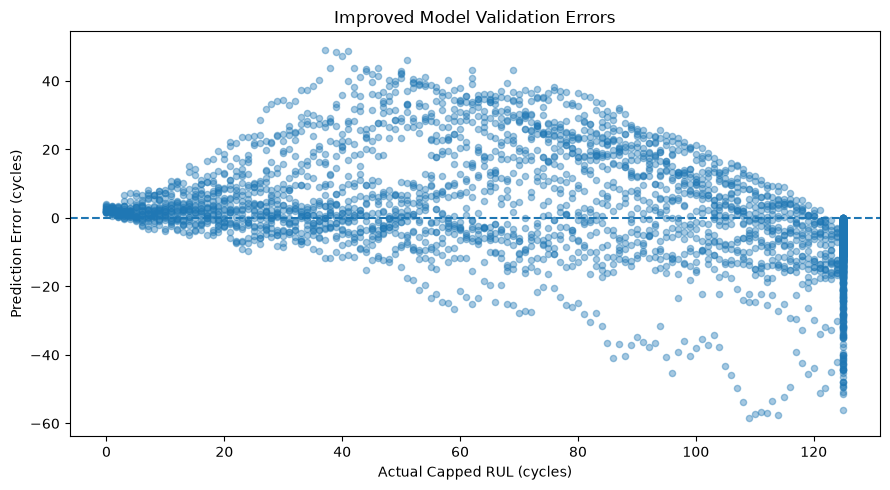

In [41]:
validation_errors = (
    best_predictions
    - y_validation_capped.to_numpy()
)

plt.figure(figsize=(9, 5))

plt.scatter(
    y_validation_capped,
    validation_errors,
    alpha=0.4,
    s=20
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Actual Capped RUL (cycles)")
plt.ylabel("Prediction Error (cycles)")
plt.title(
    "Improved Model Validation Errors"
)

plt.tight_layout()

plt.savefig(
    FIGURES_PATH /
    "improved_validation_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# testing section


In [42]:
RUL_CAPS = [100, 125, 150, 175]
cap_results = []

for cap in [100, 125, 150, 175]:

    y_capped_test = train["RUL_raw"].clip(upper=cap)

    y_train_cap = y_capped_test.iloc[train_indices]
    y_validation_cap = y_capped_test.iloc[validation_indices]

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),
            (
                "regressor",
                RandomForestRegressor(
                    n_estimators=300,
                    max_depth=None,
                    min_samples_leaf=4,
                    max_features="sqrt",
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_cap
    )

    predictions = model.predict(
        X_validation_enhanced
    )

    mae = mean_absolute_error(
        y_validation_cap,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_validation_cap,
            predictions
        )
    )

    r2 = r2_score(
        y_validation_cap,
        predictions
    )

    cap_results.append({
        "RUL_cap": cap,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

cap_results_table = pd.DataFrame(
    cap_results
).sort_values("RMSE")

cap_results_table.round(3)

,RUL_cap,MAE,RMSE,R2
0,100,6.583,10.383,0.897
1,125,10.067,14.428,0.880
2,150,13.786,18.542,0.862
3,175,16.980,22.308,0.843


In [43]:
cap_comparison = []

# Final observation for each validation engine
validation_data = train.iloc[validation_indices].copy()

validation_final_indices = (
    validation_data
    .sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .index
)

X_validation_final = train.loc[
    validation_final_indices,
    enhanced_features
]

y_validation_final_raw = train.loc[
    validation_final_indices,
    "RUL_raw"
]

for cap in [100, 125, 150, 175]:

    # Capped training target
    y_cap = train["RUL_raw"].clip(upper=cap)

    y_train_cap = y_cap.iloc[
        train_indices
    ]

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "regressor",
                RandomForestRegressor(
                    n_estimators=300,
                    max_depth=None,
                    min_samples_leaf=4,
                    max_features="sqrt",
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_cap
    )

    predictions = model.predict(
        X_validation_final
    )

    # IMPORTANT:
    # compare every model against the SAME raw RUL
    mae = mean_absolute_error(
        y_validation_final_raw,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_validation_final_raw,
            predictions
        )
    )

    r2 = r2_score(
        y_validation_final_raw,
        predictions
    )

    cap_comparison.append({
        "RUL_cap": cap,
        "MAE_raw_RUL": mae,
        "RMSE_raw_RUL": rmse,
        "R2_raw_RUL": r2
    })

fair_cap_results = pd.DataFrame(
    cap_comparison
).sort_values(
    "RMSE_raw_RUL"
)

fair_cap_results.round(3)

,RUL_cap,MAE_raw_RUL,RMSE_raw_RUL,R2_raw_RUL
3,175,2.408,2.516,0.0
1,125,2.429,2.534,0.0
0,100,2.457,2.572,0.0
2,150,2.498,2.610,0.0


In [44]:
rng = np.random.default_rng(RANDOM_STATE)

validation_engines = sorted(
    train.iloc[validation_indices]["engine_id"].unique()
)

simulated_rows = []

for engine_id in validation_engines:

    engine_data = train[
        train["engine_id"] == engine_id
    ].sort_values("cycle")

    max_cycle = engine_data["cycle"].max()

    # Pick a realistic remaining-life point
    simulated_rul = rng.integers(
        low=10,
        high=min(130, max_cycle)
    )

    observation_cycle = (
        max_cycle - simulated_rul
    )

    available_rows = engine_data[
        engine_data["cycle"] <= observation_cycle
    ]

    if len(available_rows) == 0:
        continue

    final_available_row = (
        available_rows
        .iloc[-1]
        .copy()
    )

    final_available_row["true_RUL"] = (
        max_cycle
        - final_available_row["cycle"]
    )

    simulated_rows.append(
        final_available_row
    )

simulated_validation = pd.DataFrame(
    simulated_rows
)

print(
    "Simulated validation engines:",
    len(simulated_validation)
)

simulated_validation[
    ["engine_id", "cycle", "true_RUL"]
].head()

Simulated validation engines: 20


,engine_id,cycle,true_RUL
171,1.0,172.0,20.0
1013,5.0,167.0,102.0
2287,11.0,152.0,88.0
2646,13.0,101.0,62.0
3872,19.0,97.0,61.0


In [45]:
cap_results = []

X_simulated = simulated_validation[
    enhanced_features
]

y_simulated_raw = simulated_validation[
    "true_RUL"
]

for cap in [100, 125, 150, 175]:

    y_cap = train[
        "RUL_raw"
    ].clip(
        upper=cap
    )

    y_train_cap = y_cap.iloc[
        train_indices
    ]

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "regressor",
                RandomForestRegressor(
                    n_estimators=300,
                    max_depth=None,
                    min_samples_leaf=4,
                    max_features="sqrt",
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_cap
    )

    predictions = model.predict(
        X_simulated
    )

    mae = mean_absolute_error(
        y_simulated_raw,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_simulated_raw,
            predictions
        )
    )

    r2 = r2_score(
        y_simulated_raw,
        predictions
    )

    cap_results.append({
        "RUL_cap": cap,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

simulated_cap_results = (
    pd.DataFrame(cap_results)
    .sort_values("RMSE")
)

simulated_cap_results.round(3)

,RUL_cap,MAE,RMSE,R2
0,100,13.600,18.398,0.702
1,125,14.547,19.751,0.657
2,150,16.907,22.102,0.570
3,175,18.103,24.400,0.476


# Final check


In [46]:
# Number of simulated test points per validation engine
N_TRUNCATIONS_PER_ENGINE = 10

rng = np.random.default_rng(RANDOM_STATE)

validation_engine_ids = sorted(
    train.iloc[validation_indices]["engine_id"].unique()
)

simulated_rows = []

for engine_id in validation_engine_ids:

    engine_data = (
        train[train["engine_id"] == engine_id]
        .sort_values("cycle")
        .copy()
    )

    max_cycle = engine_data["cycle"].max()

    # Possible remaining-life values for this engine
    max_possible_rul = min(130, max_cycle - 1)

    if max_possible_rul <= 10:
        continue

    # Draw several truncation points for the same engine
    simulated_ruls = rng.integers(
        low=10,
        high=max_possible_rul + 1,
        size=N_TRUNCATIONS_PER_ENGINE
    )

    for simulated_rul in simulated_ruls:

        observation_cycle = max_cycle - simulated_rul

        available_rows = engine_data[
            engine_data["cycle"] <= observation_cycle
        ]

        if len(available_rows) == 0:
            continue

        row = available_rows.iloc[-1].copy()

        row["true_RUL"] = (
            max_cycle - row["cycle"]
        )

        simulated_rows.append(row)

simulated_validation_multi = pd.DataFrame(
    simulated_rows
)

print(
    "Total simulated validation observations:",
    len(simulated_validation_multi)
)

print(
    "Number of validation engines:",
    simulated_validation_multi["engine_id"].nunique()
)

simulated_validation_multi[
    ["engine_id", "cycle", "true_RUL"]
].head()

Total simulated validation observations: 200
Number of validation engines: 20


,engine_id,cycle,true_RUL
171,1.0,172.0,20.0
88,1.0,89.0,103.0
102,1.0,103.0,89.0
128,1.0,129.0,63.0
129,1.0,130.0,62.0


In [48]:
cap_results_multi = []

X_simulated_multi = simulated_validation_multi[
    enhanced_features
]

y_simulated_multi = simulated_validation_multi[
    "true_RUL"
]

for cap in [90, 100, 125, 150, 175]:

    # Training target for this cap
    y_cap = train["RUL_raw"].clip(
        upper=cap
    )

    y_train_cap = y_cap.iloc[
        train_indices
    ]

    model = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(
                    strategy="median"
                )
            ),
            (
                "regressor",
                RandomForestRegressor(
                    n_estimators=300,
                    max_depth=None,
                    min_samples_leaf=4,
                    max_features="sqrt",
                    n_jobs=-1,
                    random_state=RANDOM_STATE
                )
            ),
        ]
    )

    model.fit(
        X_train_enhanced,
        y_train_cap
    )

    predictions = model.predict(
        X_simulated_multi
    )

    mae = mean_absolute_error(
        y_simulated_multi,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_simulated_multi,
            predictions
        )
    )

    r2 = r2_score(
        y_simulated_multi,
        predictions
    )

    cap_results_multi.append({
        "RUL_cap": cap,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

final_cap_check = (
    pd.DataFrame(cap_results_multi)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

final_cap_check.round(3)

,RUL_cap,MAE,RMSE,R2
0,100,13.201,16.551,0.752
1,125,13.242,16.834,0.743
2,90,14.830,18.467,0.691
3,150,15.626,20.112,0.633
4,175,17.637,22.635,0.535
